# Soccer Player Identification from Still Images
## Field and Team Side: separating grass from players and grouping players into teams

**What this notebook does.** Given a still image from a soccer match, it (1) finds the grass, (2) finds the people standing on it, (3) looks at the color of each person's shirt, and (4) groups the people into the two teams, the referees and the goalkeepers. It never uses a pretrained model. Every step is classical image processing from the course.

**How to read it.** Each part has a plain-language explanation first, then the code, and every code step has comments. The tags below tell you what each piece is for:

- **[PRESENTATION]** = this figure, table or idea is meant for the 4-5 minute video.
- **[ASSESSMENT]** = a question you could get on the paper assessment, with the answer in plain words.
- **[NEW CODE]** = something in the code that is new compared to your assignments. It is explained right where it appears.

**Style.** Like in the assignments, Part 3 works step by step on three example images (`image1`, `image2`, `image3`) with the code written out for each one. Parts 4 and 5 have to repeat the same steps on dozens of images and on many settings, so there I use a few **functions**. A function is just a block of code with a name, so we can reuse it instead of copy-pasting it 60 times (it is the same idea as writing the steps for `image1`, `image2` and `image3`, but for many more images).

**Where each part goes in the video (4-5 minutes)**

| Video section | Where to find it |
|---|---|
| Introduction, problem and why it matters | Part 0 text below |
| Example inputs and desired outputs | Part 2, ground-truth figure |
| Pipeline diagram | Part 0 |
| Intermediate outputs of each step | Part 3 |
| Libraries and tools used | Part 0, table below |
| Dataset description and statistics | Part 2, statistics cell |
| Preliminary results | Parts 4 and 5, results tables |
| Hyperparameters that affect the results | Part 4 (detection) and Part 5 (teams) |
| Success and failure examples | Part 6 |
| Sources of error, conclusion, future work | Part 7 |

**Libraries used (say this in the video and in the assessment)**

| Library | What we use it for | Own work or library? |
|---|---|---|
| OpenCV (`cv2`) | color conversion, morphology, connected components, convex hull, K-means | the algorithms are the library's; **choosing and combining the steps and all the settings is our own design** |
| NumPy | arrays and counting | library |
| Matplotlib | figures | library |
| `huggingface_hub`, `zipfile`, `json` | reading a few frames and labels out of the big dataset file | library |

In [ ]:
import os
import json
import glob
import zipfile
import random
import numpy as np
import matplotlib.pyplot as plt
import cv2

# PART 0 - The Problem and the Pipeline

**The problem.** Photographers, media teams and analysts still mark players in match photos by hand, and cheap automatic tools are rare for amateur and youth teams. Our project identifies players in a still photo by team (shirt color) and by jersey number. *This notebook covers the first half: finding the people on the field and sorting them into teams, referees and goalkeepers.* My partner covers the jersey numbers.

**Why it is worth solving.** Doing this by hand for hundreds of photos is slow, and professional tracking systems are expensive.

**The idea in one sentence.** A soccer pitch is mostly green, so everything that is *not* green inside the pitch is a person (or a line). Then people wear shirts of different colors, so grouping the shirt colors gives us the teams.

## [PRESENTATION] Pipeline diagram

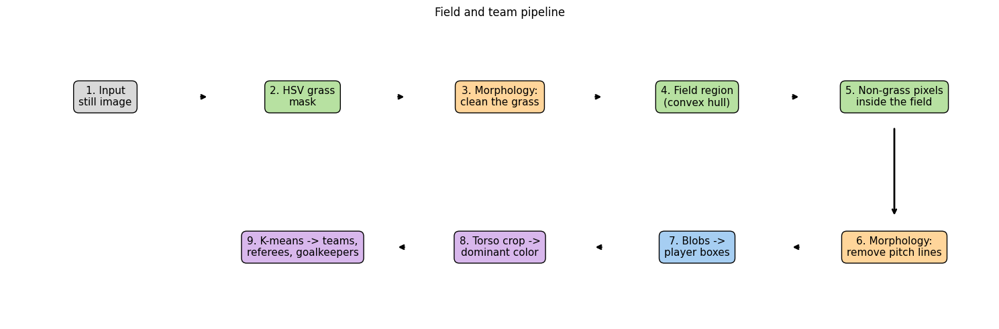

In [ ]:
#Pipeline diagram drawn with boxes and arrows
steps = [
    "1. Input\nstill image",
    "2. HSV grass\nmask",
    "3. Morphology:\nclean the grass",
    "4. Field region\n(convex hull)",
    "5. Non-grass pixels\ninside the field",
    "6. Morphology:\nremove pitch lines",
    "7. Blobs ->\nplayer boxes",
    "8. Torso crop ->\ndominant color",
    "9. K-means -> teams,\nreferees, goalkeepers",
]

#Position of each box (first row left to right, second row right to left)
xs = [1, 3, 5, 7, 9, 9, 7, 5, 3]
ys = [3, 3, 3, 3, 3, 1, 1, 1, 1]

#Box colors: grass steps, morphology steps, blob steps, color and team steps
colors = ["#d9d9d9", "#b7e1a1", "#ffd59a", "#b7e1a1", "#b7e1a1", "#ffd59a", "#a6cef2", "#d8b7ec", "#d8b7ec"]

plt.figure(figsize=(15, 5))
ax = plt.gca()
ax.set_xlim(0, 10)
ax.set_ylim(0, 4)
ax.axis("off")

for i in range(len(steps)):
    ax.text(xs[i], ys[i], steps[i], ha="center", va="center", fontsize=11,
            bbox=dict(boxstyle="round,pad=0.5", facecolor=colors[i], edgecolor="black"))

#Arrows between consecutive boxes
for i in range(len(steps) - 1):
    if ys[i] == ys[i + 1]:
        direction = 1 if xs[i + 1] > xs[i] else -1
        start = (xs[i] + direction * 0.95, ys[i])
        end = (xs[i + 1] - direction * 0.95, ys[i + 1])
    else:
        start = (xs[i], ys[i] - 0.4)
        end = (xs[i + 1], ys[i + 1] + 0.4)
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->", lw=2))

plt.title("Field and team pipeline")
plt.tight_layout()
plt.show()

> **[ASSESSMENT] Pipeline in one breath (practice saying this out loud).**
> "I convert the image to HSV and threshold the green hue to get the grass. Morphological opening removes tiny grass specks, a closing reconnects the pieces that the pitch lines split, I keep the biggest grass piece and take its convex hull as the field region. Inside the field, anything that is not grass is a candidate: people, pitch lines, the ball. Opening removes the thin pitch lines, closing joins the pieces of one player. Connected components turn the remaining white regions into blobs and I keep the ones with a plausible size and shape as player boxes. For each box I crop the torso, keep the non-grass pixels, and take the most common quantized color as the shirt color. Finally K-means groups those colors into teams, referees and goalkeepers."

# PART 1 - Getting the Data

**Dataset.** SoccerNet Game State Reconstruction (SoccerNet-GSR). It has 30-second broadcast clips and, for every frame, a box around each person with a role (player, goalkeeper, referee, other), a team (left or right) and sometimes a jersey number.

**Why this dataset.** It is real broadcast footage with labels for exactly what we need, so we can measure our results. It comes from the benchmark used in the papers of my literature review.

**The problem with the data.** The whole validation set is one file of about 11 GB. We do not need all of it for a classical pipeline with no training. So instead of downloading it, the code reads the table of contents of the file over the internet and takes only a few clips: their label files and a handful of frames.

**How the sample is made (the sub-sampling procedure).**
1. List all the clips in the file, shuffle them with a fixed random seed (so anyone gets the same clips) and take the first few. This avoids picking clips by hand, so we do not choose only the easy ones.
2. In each clip take frames evenly spaced in time, so the frames are far apart and are not nearly the same picture. Each frame is then treated as an **independent still image**, as promised in the proposal.
3. Save the frames and a small label file to disk, so the next runs do not use the internet.

> **[ASSESSMENT] Data collection and fitness.**
> *How did you collect the data?* I sub-sampled SoccerNet-GSR: random clips (fixed seed) and evenly spaced frames from each, read directly from the dataset file.
> *Why is it appropriate?* It is real broadcast footage with player boxes, roles and teams, which is exactly what I need for evaluation.
> *Is the sample representative?* It covers several different matches (different stadiums, kits and lighting), but it is small and only from the validation split, so results are indicative and not a full benchmark.

In [ ]:
#Settings for sampling the data (change these to get more or fewer images)
data_dir = "sampled_data"          #folder where the sampled frames and labels are saved
num_sequences = 6                  #how many 30-second clips are used
frames_per_sequence = 10           #how many frames are taken from each clip

os.makedirs(data_dir, exist_ok=True)

#Clips that were already saved in a previous run
saved_labels = glob.glob(os.path.join(data_dir, "*", "labels.json"))
print("Clips already saved:", len(saved_labels), "of", num_sequences)

Clips already saved: 6 of 6


In [ ]:
#This cell only uses the internet if some clips are still missing
if len(saved_labels) >= num_sequences:
    print("Nothing to download, using the saved data")
else:
    #Longer waiting time for slow connections (must be set before importing huggingface_hub)
    os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "60"
    from huggingface_hub import HfFileSystem

    #Opening the remote zip file. Nothing big is downloaded here: Python only asks for the parts it needs
    fs = HfFileSystem()
    remote_file = fs.open("datasets/SoccerNet/SN-GSR-2024/valid.zip", "rb", block_size=2 * 1024 * 1024)
    z = zipfile.ZipFile(remote_file)
    names = z.namelist()             #list of all the files inside the zip
    name_set = set(names)            #same list as a set, which is much faster to search

    #There is one label file per clip, so the label files give us the list of clips
    label_names = []
    for n in names:
        if n.endswith("Labels-GameState.json"):
            label_names.append(n)
    label_names = sorted(label_names)
    print("Clips available in the zip:", len(label_names))

    #Shuffling with a fixed seed and taking the first ones (same clips every time)
    random.seed(481)
    random.shuffle(label_names)
    chosen = label_names[:num_sequences]

    for label_name in chosen:
        seq_folder = label_name.rsplit("/", 1)[0]       #folder of the clip inside the zip
        seq_name = os.path.basename(seq_folder)         #name of the clip, for example SNGS-021
        seq_dir = os.path.join(data_dir, seq_name)      #where we save it on disk

        if os.path.exists(os.path.join(seq_dir, "labels.json")):
            print("Already saved:", seq_name)
            continue

        print("Downloading:", seq_name)
        try:
            os.makedirs(os.path.join(seq_dir, "frames"), exist_ok=True)

            #Only the bytes of this one label file are downloaded
            labels = json.loads(z.read(label_name))

            #Frames in time order, then evenly spaced frames
            images = sorted(labels["images"], key=lambda im: im["file_name"])
            step = max(1, len(images) // frames_per_sequence)

            saved = []
            for img in images[::step][:frames_per_sequence]:
                #Boxes of the people in this frame (the other annotations are the pitch lines and the camera)
                boxes = []
                for a in labels["annotations"]:
                    if a["supercategory"] == "object" and a["image_id"] == img["image_id"]:
                        box = {
                            "role": a["attributes"].get("role"),
                            "team": a["attributes"].get("team"),
                            "jersey": a["attributes"].get("jersey"),
                            "x": a["bbox_image"]["x"], "y": a["bbox_image"]["y"],
                            "w": a["bbox_image"]["w"], "h": a["bbox_image"]["h"],
                        }
                        boxes.append(box)
                if len(boxes) == 0:
                    continue

                #Frames are inside the img1 folder of the clip
                frame_path = seq_folder + "/img1/" + img["file_name"]
                if frame_path not in name_set:
                    frame_path = seq_folder + "/" + img["file_name"]

                file_name = os.path.basename(img["file_name"])
                with open(os.path.join(seq_dir, "frames", file_name), "wb") as f:
                    f.write(z.read(frame_path))         #only the bytes of this one frame are downloaded
                saved.append({"file_name": file_name, "boxes": boxes})

            #labels.json is written last, so a clip only counts as saved when all its frames are saved
            with open(os.path.join(seq_dir, "labels.json"), "w") as f:
                json.dump(saved, f)
            print("   saved", len(saved), "frames")

        except Exception as e:
            print("Failed:", seq_name, "-", e, "(run this cell again to retry)")

Nothing to download, using the saved data


# PART 2 - Looking at the Data

Loading the saved frames and labels into one list called `frames`. Each item of the list is a **dictionary**, which stores values under names, so `f["image"]` is the image of that frame and `f["boxes"]` are its ground-truth boxes.

For every person we also store a **label**, the group the dataset says the person belongs to (for example `player_left` or `referee`). We use it later only to measure our results.

In [ ]:
#Loading all the saved frames
frames = []
seq_names = []          #names of the clips, in order

for labels_path in sorted(glob.glob(os.path.join(data_dir, "*", "labels.json"))):
    seq_dir = os.path.dirname(labels_path)
    seq_name = os.path.basename(seq_dir)
    seq_names.append(seq_name)

    with open(labels_path) as f:
        saved = json.load(f)

    for item in saved:
        image = cv2.imread(os.path.join(seq_dir, "frames", item["file_name"]))
        if image is None:
            continue

        #Adding the group (label) to every ground-truth box
        people = []              #players, goalkeepers and referees (the "other" people are not part of our task)
        for b in item["boxes"]:
            if b["role"] == "player":
                b["label"] = "player_" + str(b["team"])
            elif b["role"] == "goalkeeper":
                b["label"] = "goalkeeper_" + str(b["team"])
            else:
                b["label"] = b["role"]          #referee or other

            if b["role"] in ["player", "goalkeeper", "referee"]:
                people.append(b)

        frames.append({"name": seq_name + "_" + item["file_name"], "seq": seq_name, "clip_id": len(seq_names) - 1,
                       "image": image, "boxes": item["boxes"], "people": people})

print("Frames loaded:", len(frames))

Frames loaded: 60


## [PRESENTATION] Dataset statistics

Ballpark numbers are enough for the assessment, but know the pattern: *a few clips, tens of frames, 20-30 people per frame, and many small players.*

Clips (different matches): 6
Frames: 60
Image size (height, width, channels): (1080, 1920, 3)
Players: 802 , goalkeepers: 39 , referees: 75 , others: 59
Players - left team: 386 , right team: 416
People per frame: min 6 , median 17 , max 23
Player box height in pixels: min 13 , median 121 , max 255


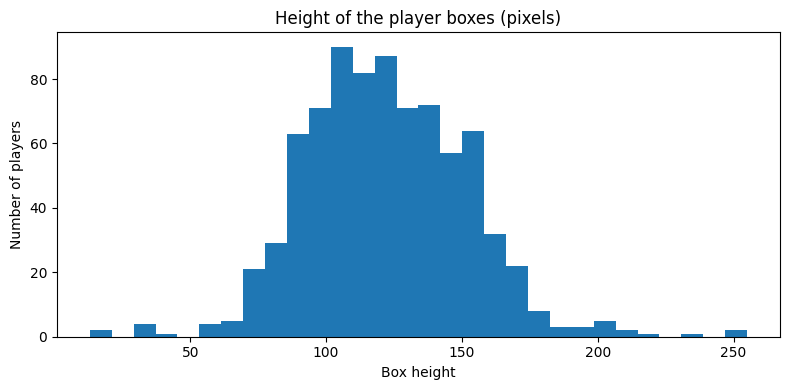

In [ ]:
#Dataset statistics
print("Clips (different matches):", len(seq_names))
print("Frames:", len(frames))
print("Image size (height, width, channels):", frames[0]["image"].shape)

#Number of boxes for each role, and players for each team
count_player = 0
count_goalkeeper = 0
count_referee = 0
count_other = 0
left_players = 0
right_players = 0
people_per_frame = []
player_heights = []

for f in frames:
    people_per_frame.append(len(f["boxes"]))
    for b in f["boxes"]:
        if b["role"] == "player":
            count_player += 1
            player_heights.append(b["h"])
            if b["team"] == "left":
                left_players += 1
            else:
                right_players += 1
        elif b["role"] == "goalkeeper":
            count_goalkeeper += 1
        elif b["role"] == "referee":
            count_referee += 1
        else:
            count_other += 1

print("Players:", count_player, ", goalkeepers:", count_goalkeeper, ", referees:", count_referee, ", others:", count_other)
print("Players - left team:", left_players, ", right team:", right_players)
print("People per frame: min", min(people_per_frame), ", median", int(np.median(people_per_frame)), ", max", max(people_per_frame))
print("Player box height in pixels: min", int(min(player_heights)), ", median", int(np.median(player_heights)), ", max", int(max(player_heights)))

#How tall are the players? Small players are hard to work with
plt.figure(figsize=(8, 4))
plt.hist(player_heights, bins=30)
plt.title("Height of the player boxes (pixels)")
plt.xlabel("Box height")
plt.ylabel("Number of players")
plt.tight_layout()
plt.show()

## [PRESENTATION] Example inputs and desired outputs

Three input frames from different matches (top row) and what we want to get (bottom row): a box around every person, colored by group. The bottom row is the **ground truth** from the dataset: red and blue = the two teams (left and right), yellow = goalkeepers, magenta = referees, white = other people.

From here on, `image1`, `image2` and `image3` are these three example frames (the middle frame of the first three clips).

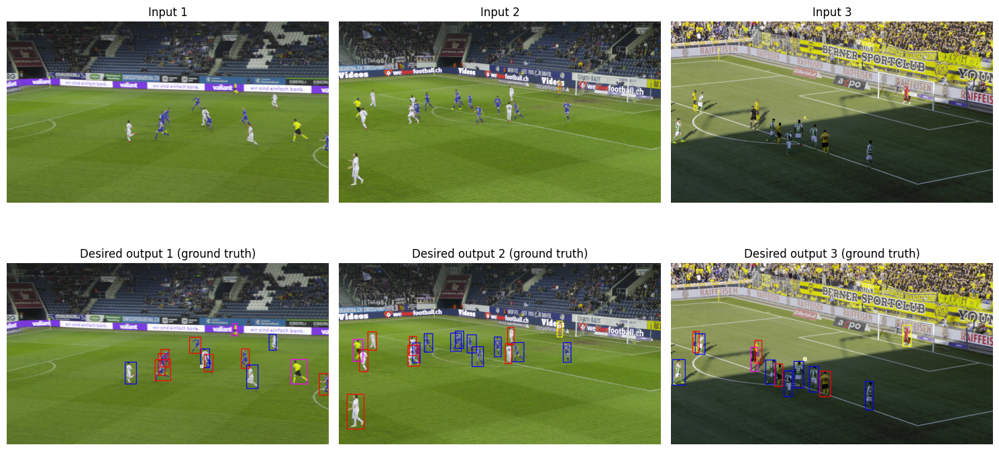

In [ ]:
#Choosing the middle frame of the first three clips as the example images
demo_ids = []
for c in range(3):
    ids = []
    for i in range(len(frames)):
        if frames[i]["clip_id"] == c:
            ids.append(i)
    demo_ids.append(ids[len(ids) // 2])

image1 = frames[demo_ids[0]]["image"]
image2 = frames[demo_ids[1]]["image"]
image3 = frames[demo_ids[2]]["image"]

#Converting BGR to RGB for display
image1_rgb = cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)
image2_rgb = cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)
image3_rgb = cv2.cvtColor(image3, cv2.COLOR_BGR2RGB)
demo_rgb = [image1_rgb, image2_rgb, image3_rgb]

#Colors (RGB) for each group of people in the ground truth
gt_colours = {
    "player_left": (255, 0, 0),
    "player_right": (0, 0, 255),
    "goalkeeper_left": (255, 255, 0),
    "goalkeeper_right": (255, 255, 0),
    "referee": (255, 0, 255),
    "other": (255, 255, 255),
}

#Drawing the ground-truth boxes on a copy of each example image
gt_drawn = []
for k in range(3):
    drawn = demo_rgb[k].copy()
    for b in frames[demo_ids[k]]["boxes"]:
        x = int(b["x"])
        y = int(b["y"])
        w = int(b["w"])
        h = int(b["h"])
        cv2.rectangle(drawn, (x, y), (x + w, y + h), gt_colours.get(b["label"], (255, 255, 255)), 3)
    gt_drawn.append(drawn)

plt.figure(figsize=(15, 8))

for k in range(3):
    plt.subplot(2, 3, k + 1)
    plt.imshow(demo_rgb[k])
    plt.title("Input " + str(k + 1))
    plt.axis("off")

    plt.subplot(2, 3, k + 4)
    plt.imshow(gt_drawn[k])
    plt.title("Desired output " + str(k + 1) + " (ground truth)")
    plt.axis("off")

plt.tight_layout()
plt.show()

> **[ASSESSMENT] Dataset questions.**
> *Ballpark size?* Around 6 clips and 60 frames, with about 20-30 people per frame, so well over a thousand labeled people.
> *Class distribution?* Most boxes are players, split roughly evenly between the two teams; goalkeepers and referees are a small minority.
> *Noise in the images?* Broadcast footage: motion blur when the camera pans, shadows and uneven light on the grass, players overlapping each other, many players that are tiny because they are far from the camera, and advertising boards and crowds around the pitch.
> *Why is there no training data?* This half of the project uses no learning: color thresholds, morphology and K-means need no labeled training set. The labels are only used to **measure** how well it works.

# PART 3 - The Pipeline Step by Step (on the 3 example images)

Every step is shown on the same three images (`image1`, `image2`, `image3`), so you can see what each step does. In Part 4 the same steps are packaged into a function to run them on all the frames.

# (a) Step 1 - Finding the grass with HSV

**Why not RGB?** In RGB, the color of the grass and how bright it is are mixed together. The grass on a pitch has bright parts, shadows and mowing stripes, so its RGB values change a lot. In **HSV** the color is separated from the brightness:

- **H (hue)** = which color it is. In OpenCV it goes from 0 to 179. Green is around 60.
- **S (saturation)** = how pure the color is. Low saturation = grey or white.
- **V (value)** = how bright it is.

The grass keeps almost the same hue even in shadow. So we select pixels whose hue is in the green range, and we also require some minimum saturation and brightness, so that white lines, grey crowds and very dark areas are not selected.

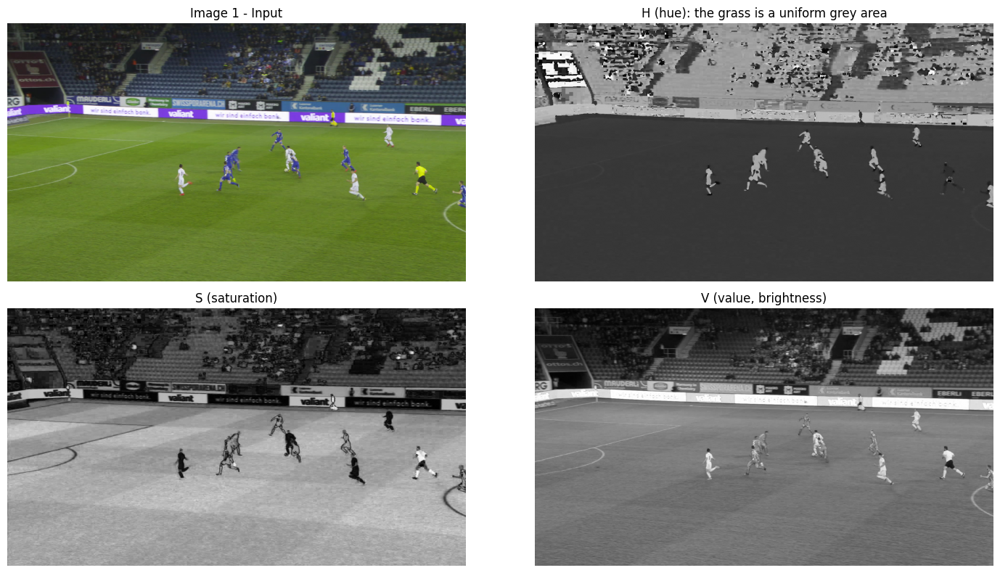

In [ ]:
#Looking at the H, S and V channels of image 1
hsv1 = cv2.cvtColor(image1, cv2.COLOR_BGR2HSV)

plt.figure(figsize=(15, 8))

plt.subplot(2, 2, 1)
plt.imshow(image1_rgb)
plt.title("Image 1 - Input")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(hsv1[:, :, 0], cmap="gray")
plt.title("H (hue): the grass is a uniform grey area")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(hsv1[:, :, 1], cmap="gray")
plt.title("S (saturation)")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(hsv1[:, :, 2], cmap="gray")
plt.title("V (value, brightness)")
plt.axis("off")

plt.tight_layout()
plt.show()

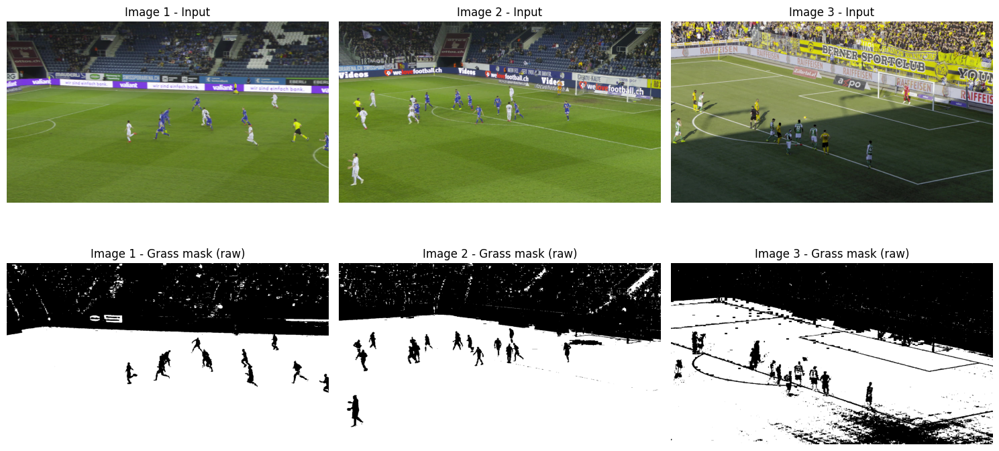

In [ ]:
#Grass thresholds (OpenCV: H in 0-179, S and V in 0-255). These are the settings we will test later
hue_low = 35
hue_high = 85
sat_min = 40
val_min = 40

#Grass mask for each image: white (255) = grass, black (0) = not grass
hsv1 = cv2.cvtColor(image1, cv2.COLOR_BGR2HSV)
hsv2 = cv2.cvtColor(image2, cv2.COLOR_BGR2HSV)
hsv3 = cv2.cvtColor(image3, cv2.COLOR_BGR2HSV)

grass_raw1 = ((hsv1[:, :, 0] >= hue_low) & (hsv1[:, :, 0] <= hue_high) & (hsv1[:, :, 1] >= sat_min) & (hsv1[:, :, 2] >= val_min)).astype(np.uint8) * 255
grass_raw2 = ((hsv2[:, :, 0] >= hue_low) & (hsv2[:, :, 0] <= hue_high) & (hsv2[:, :, 1] >= sat_min) & (hsv2[:, :, 2] >= val_min)).astype(np.uint8) * 255
grass_raw3 = ((hsv3[:, :, 0] >= hue_low) & (hsv3[:, :, 0] <= hue_high) & (hsv3[:, :, 1] >= sat_min) & (hsv3[:, :, 2] >= val_min)).astype(np.uint8) * 255

plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(image1_rgb)
plt.title("Image 1 - Input")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(image2_rgb)
plt.title("Image 2 - Input")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(image3_rgb)
plt.title("Image 3 - Input")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(grass_raw1, cmap="gray")
plt.title("Image 1 - Grass mask (raw)")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(grass_raw2, cmap="gray")
plt.title("Image 2 - Grass mask (raw)")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(grass_raw3, cmap="gray")
plt.title("Image 3 - Grass mask (raw)")
plt.axis("off")

plt.tight_layout()
plt.show()

**What to notice.** The players show up as black "holes" inside the white grass area. The pitch lines are also black thin lines. There may be small white specks outside the pitch (green things in the crowd or advertising). Next we clean those.

### [PRESENTATION] How the grass settings change the mask
The hue range and the minimum saturation are the first settings that affect the result. A range that is too narrow loses parts of the grass (sunny or shaded areas); a range that is too wide starts to include other colors.

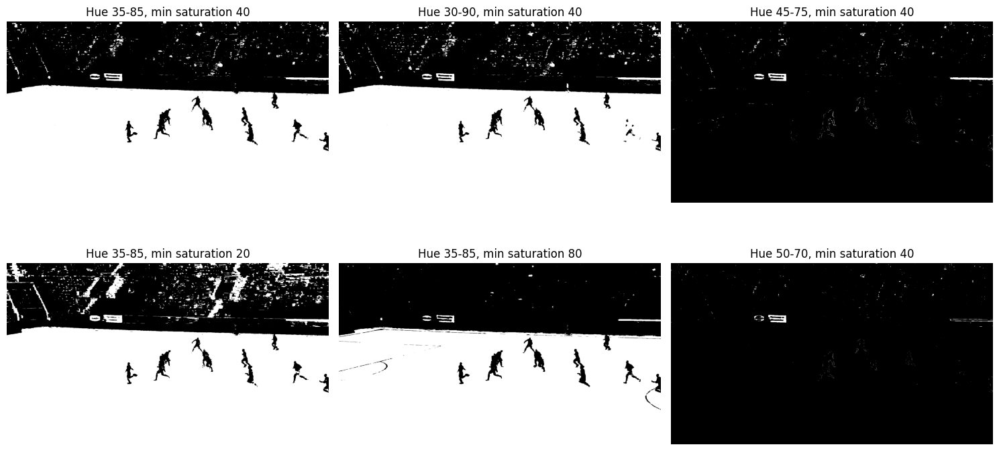

In [ ]:
#Trying different grass settings on image 1: (hue low, hue high, minimum saturation)
settings = [(35, 85, 40), (30, 90, 40), (45, 75, 40), (35, 85, 20), (35, 85, 80), (50, 70, 40)]

plt.figure(figsize=(15, 8))

for k in range(len(settings)):
    h_low = settings[k][0]
    h_high = settings[k][1]
    s_min = settings[k][2]
    mask = ((hsv1[:, :, 0] >= h_low) & (hsv1[:, :, 0] <= h_high) & (hsv1[:, :, 1] >= s_min) & (hsv1[:, :, 2] >= val_min)).astype(np.uint8) * 255

    plt.subplot(2, 3, k + 1)
    plt.imshow(mask, cmap="gray")
    plt.title("Hue " + str(h_low) + "-" + str(h_high) + ", min saturation " + str(s_min))
    plt.axis("off")

plt.tight_layout()
plt.show()

> **[ASSESSMENT] Grass mask.**
> *Why HSV?* It separates color (hue) from brightness, so grass in sun and in shadow still has about the same hue. In RGB all three channels change with brightness.
> *What do the thresholds do?* Hue 35-85 keeps green. The minimum saturation removes whites and greys (lines, crowd, overcast areas). The minimum value removes very dark pixels.
> *How did you choose them?* By looking at the masks on several frames (the figure above) and then measuring detection quality for a few settings (Part 4).
> *What goes wrong?* Pitches with yellowish or very dark grass, strong shadows, and players wearing green (their shirt is classified as grass).

# (b) Step 2 - Cleaning the grass mask and finding the field region

Four operations, each from the morphology lecture:

1. **Opening** (erosion followed by dilation) with a small elliptical structuring element removes the tiny grass specks outside the pitch. Opening removes small objects and keeps the big ones.
2. **Closing** (dilation followed by erosion) with a bigger structuring element **only to find the pitch**. The white pitch lines (for example the halfway line) cut across the whole pitch and split the grass into several pieces. Closing is wider than a line, so it reconnects those pieces.
3. **Largest connected component.** After the closing, the pitch is by far the biggest piece, so we keep only that one.
4. **Convex hull.** The players are holes inside the grass. The convex hull is the smallest convex shape that contains the whole grass region, so it fills those holes (and the lines). The result is the **field region**: everything inside the pitch, grass or not.

Important: the closing is used only to locate the pitch. The grass mask we keep for the next steps is the one after the opening, so the players are still holes in it.

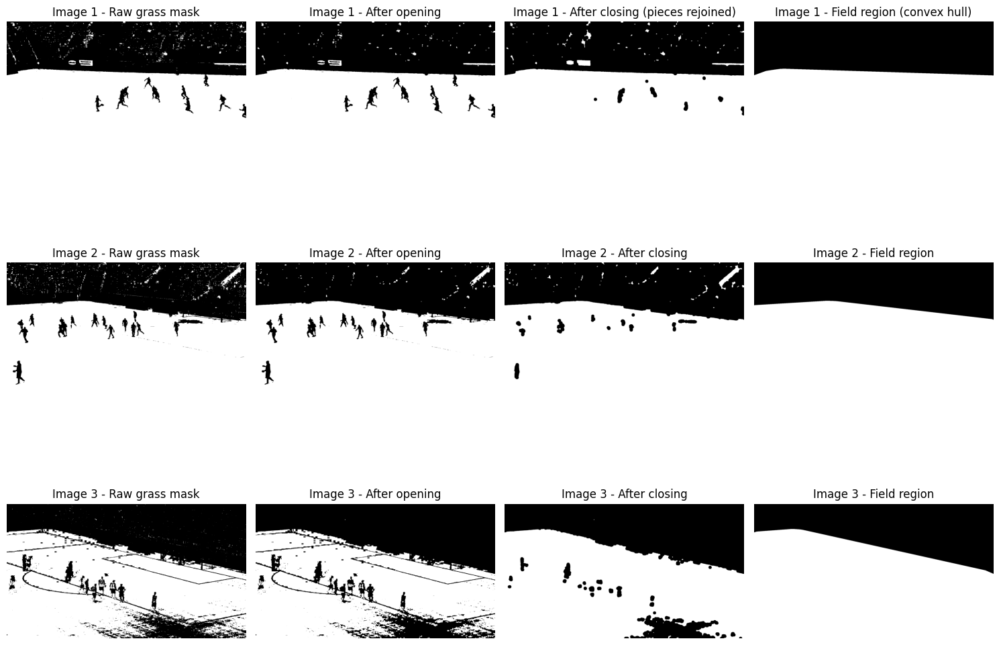

In [ ]:
#Elliptical structuring elements: a small one for the opening, a big one (wider than a pitch line) for the closing
kernel_grass = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
kernel_pitch = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25))

#1. Opening removes the tiny specks
grass_open1 = cv2.morphologyEx(grass_raw1, cv2.MORPH_OPEN, kernel_grass)
grass_open2 = cv2.morphologyEx(grass_raw2, cv2.MORPH_OPEN, kernel_grass)
grass_open3 = cv2.morphologyEx(grass_raw3, cv2.MORPH_OPEN, kernel_grass)

#2. Closing reconnects the grass pieces that the pitch lines split apart
grass_joined1 = cv2.morphologyEx(grass_open1, cv2.MORPH_CLOSE, kernel_pitch)
grass_joined2 = cv2.morphologyEx(grass_open2, cv2.MORPH_CLOSE, kernel_pitch)
grass_joined3 = cv2.morphologyEx(grass_open3, cv2.MORPH_CLOSE, kernel_pitch)

#3. Connected components: label 0 is the background, the others are the grass pieces.
#stats[i, cv2.CC_STAT_AREA] is the number of pixels of piece i. We keep the piece with the biggest area
num1, labels1, stats1, centroids1 = cv2.connectedComponentsWithStats(grass_joined1, connectivity=8)
num2, labels2, stats2, centroids2 = cv2.connectedComponentsWithStats(grass_joined2, connectivity=8)
num3, labels3, stats3, centroids3 = cv2.connectedComponentsWithStats(grass_joined3, connectivity=8)

biggest1 = 1 + np.argmax(stats1[1:, cv2.CC_STAT_AREA])      #[1:] skips the background
biggest2 = 1 + np.argmax(stats2[1:, cv2.CC_STAT_AREA])
biggest3 = 1 + np.argmax(stats3[1:, cv2.CC_STAT_AREA])

pitch1 = (labels1 == biggest1).astype(np.uint8) * 255
pitch2 = (labels2 == biggest2).astype(np.uint8) * 255
pitch3 = (labels3 == biggest3).astype(np.uint8) * 255

#4. Convex hull: first the outline (contour) of the pitch, then the hull of that outline.
#[NEW CODE] max(contours, key=cv2.contourArea) picks the contour with the biggest area
contours1, _ = cv2.findContours(pitch1, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contours2, _ = cv2.findContours(pitch2, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contours3, _ = cv2.findContours(pitch3, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

hull1 = cv2.convexHull(max(contours1, key=cv2.contourArea))
hull2 = cv2.convexHull(max(contours2, key=cv2.contourArea))
hull3 = cv2.convexHull(max(contours3, key=cv2.contourArea))

#Filling the hull with white to get the field region mask
field1 = np.zeros_like(grass_open1)
field2 = np.zeros_like(grass_open2)
field3 = np.zeros_like(grass_open3)
cv2.fillConvexPoly(field1, hull1, 255)
cv2.fillConvexPoly(field2, hull2, 255)
cv2.fillConvexPoly(field3, hull3, 255)

#Displaying the steps for the three images
plt.figure(figsize=(15, 12))

plt.subplot(3, 4, 1)
plt.imshow(grass_raw1, cmap="gray")
plt.title("Image 1 - Raw grass mask")
plt.axis("off")

plt.subplot(3, 4, 2)
plt.imshow(grass_open1, cmap="gray")
plt.title("Image 1 - After opening")
plt.axis("off")

plt.subplot(3, 4, 3)
plt.imshow(grass_joined1, cmap="gray")
plt.title("Image 1 - After closing (pieces rejoined)")
plt.axis("off")

plt.subplot(3, 4, 4)
plt.imshow(field1, cmap="gray")
plt.title("Image 1 - Field region (convex hull)")
plt.axis("off")

plt.subplot(3, 4, 5)
plt.imshow(grass_raw2, cmap="gray")
plt.title("Image 2 - Raw grass mask")
plt.axis("off")

plt.subplot(3, 4, 6)
plt.imshow(grass_open2, cmap="gray")
plt.title("Image 2 - After opening")
plt.axis("off")

plt.subplot(3, 4, 7)
plt.imshow(grass_joined2, cmap="gray")
plt.title("Image 2 - After closing")
plt.axis("off")

plt.subplot(3, 4, 8)
plt.imshow(field2, cmap="gray")
plt.title("Image 2 - Field region")
plt.axis("off")

plt.subplot(3, 4, 9)
plt.imshow(grass_raw3, cmap="gray")
plt.title("Image 3 - Raw grass mask")
plt.axis("off")

plt.subplot(3, 4, 10)
plt.imshow(grass_open3, cmap="gray")
plt.title("Image 3 - After opening")
plt.axis("off")

plt.subplot(3, 4, 11)
plt.imshow(grass_joined3, cmap="gray")
plt.title("Image 3 - After closing")
plt.axis("off")

plt.subplot(3, 4, 12)
plt.imshow(field3, cmap="gray")
plt.title("Image 3 - Field region")
plt.axis("off")

plt.tight_layout()
plt.show()

**What to notice.** The field region should cover the pitch and not the stands or the sky. If the camera shows a corner of the pitch that is not convex, or a big grass-colored object appears elsewhere, the hull can be wrong. That is a failure case worth looking for.

> **[ASSESSMENT] Morphology and hull.**
> *What is opening and why here?* Erosion then dilation. Erosion shrinks white regions and removes anything smaller than the structuring element; dilation then grows the survivors back. So small specks disappear and the big pitch stays almost unchanged.
> *Why a closing before finding the biggest piece?* The white lines (the halfway line, for example) cross the whole pitch and cut the grass mask into several pieces. A closing wider than a line reconnects them, so the biggest piece is the whole pitch and not just one part of it. It is used only to find the pitch: the grass mask used afterwards is the one without the closing.
> *Why the convex hull?* The people are holes in the grass mask. The hull fills those holes in one step and gives us the area where people can be.
> *Why not use a closing to fill the players?* A closing big enough to fill a player would also change the shape of the pitch, and players have different sizes. The hull does not depend on player size.

# (c) Step 3 - People = non-grass pixels inside the field

Inside the field region, every pixel that is not grass belongs to a player, a referee, the ball or a pitch line. So:

**non-grass inside the field = field region AND NOT grass**

Then two more morphology steps:

- **Opening with a bigger structuring element** removes the thin pitch lines (they are only a few pixels wide) and tiny noise, but players are thick enough to survive.
- **Closing with a small structuring element** joins the pieces of the same player that came apart (for example, a gap between the shirt and the shorts).

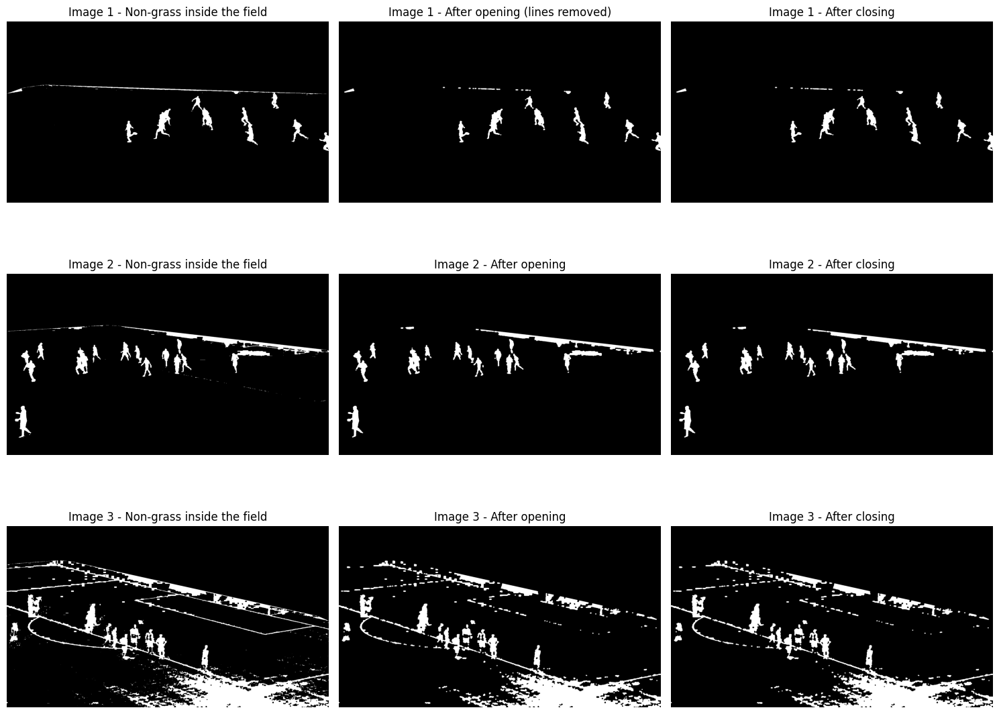

In [ ]:
kernel_people_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
kernel_people_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

#Inside the field AND NOT grass (bitwise_not turns white into black and black into white)
non_grass_raw1 = cv2.bitwise_and(field1, cv2.bitwise_not(grass_open1))
non_grass_raw2 = cv2.bitwise_and(field2, cv2.bitwise_not(grass_open2))
non_grass_raw3 = cv2.bitwise_and(field3, cv2.bitwise_not(grass_open3))

#Opening removes the thin pitch lines and noise
non_grass_open1 = cv2.morphologyEx(non_grass_raw1, cv2.MORPH_OPEN, kernel_people_open)
non_grass_open2 = cv2.morphologyEx(non_grass_raw2, cv2.MORPH_OPEN, kernel_people_open)
non_grass_open3 = cv2.morphologyEx(non_grass_raw3, cv2.MORPH_OPEN, kernel_people_open)

#Closing joins the pieces of the same player
non_grass_clean1 = cv2.morphologyEx(non_grass_open1, cv2.MORPH_CLOSE, kernel_people_close)
non_grass_clean2 = cv2.morphologyEx(non_grass_open2, cv2.MORPH_CLOSE, kernel_people_close)
non_grass_clean3 = cv2.morphologyEx(non_grass_open3, cv2.MORPH_CLOSE, kernel_people_close)

plt.figure(figsize=(15, 12))

plt.subplot(3, 3, 1)
plt.imshow(non_grass_raw1, cmap="gray")
plt.title("Image 1 - Non-grass inside the field")
plt.axis("off")

plt.subplot(3, 3, 2)
plt.imshow(non_grass_open1, cmap="gray")
plt.title("Image 1 - After opening (lines removed)")
plt.axis("off")

plt.subplot(3, 3, 3)
plt.imshow(non_grass_clean1, cmap="gray")
plt.title("Image 1 - After closing")
plt.axis("off")

plt.subplot(3, 3, 4)
plt.imshow(non_grass_raw2, cmap="gray")
plt.title("Image 2 - Non-grass inside the field")
plt.axis("off")

plt.subplot(3, 3, 5)
plt.imshow(non_grass_open2, cmap="gray")
plt.title("Image 2 - After opening")
plt.axis("off")

plt.subplot(3, 3, 6)
plt.imshow(non_grass_clean2, cmap="gray")
plt.title("Image 2 - After closing")
plt.axis("off")

plt.subplot(3, 3, 7)
plt.imshow(non_grass_raw3, cmap="gray")
plt.title("Image 3 - Non-grass inside the field")
plt.axis("off")

plt.subplot(3, 3, 8)
plt.imshow(non_grass_open3, cmap="gray")
plt.title("Image 3 - After opening")
plt.axis("off")

plt.subplot(3, 3, 9)
plt.imshow(non_grass_clean3, cmap="gray")
plt.title("Image 3 - After closing")
plt.axis("off")

plt.tight_layout()
plt.show()

# (d) Step 4 - From white regions to player boxes

**Connected components** again: each white region becomes one blob and OpenCV gives us its bounding box and its area. Then we keep only blobs that look like a person:

- not too small (area and height), to drop noise and far-away specks,
- not too big (a blob bigger than 5% of the image is not a player),
- taller than wide (height/width between 0.8 and 5), since a standing person is a tall shape.

Players who touch or overlap end up in **one** blob. That is a known weakness we will see in the failure cases.

The boxes we draw here are in **red**; the ground truth is in thin **white**.

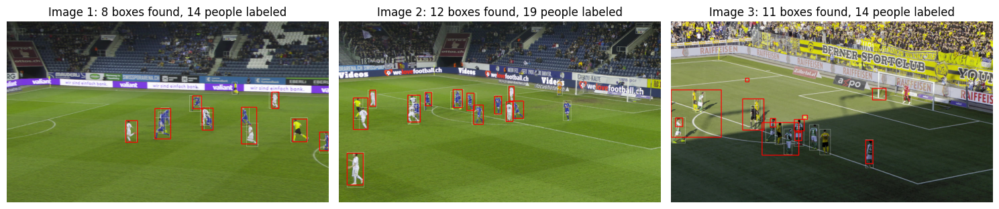

In [ ]:
#Settings for choosing the blobs that look like people
min_area = 300
min_height = 20
min_aspect = 0.8       #height / width
max_aspect = 5.0
max_area_fraction = 0.05

#Connected components of the cleaned masks
num1, labels1, stats1, centroids1 = cv2.connectedComponentsWithStats(non_grass_clean1, connectivity=8)
num2, labels2, stats2, centroids2 = cv2.connectedComponentsWithStats(non_grass_clean2, connectivity=8)
num3, labels3, stats3, centroids3 = cv2.connectedComponentsWithStats(non_grass_clean3, connectivity=8)

#Image 1: keeping only the blobs that look like a person
boxes1 = []
img_h1, img_w1 = non_grass_clean1.shape
for i in range(1, num1):                         #label 0 is the background
    x = int(stats1[i, cv2.CC_STAT_LEFT])
    y = int(stats1[i, cv2.CC_STAT_TOP])
    w = int(stats1[i, cv2.CC_STAT_WIDTH])
    h = int(stats1[i, cv2.CC_STAT_HEIGHT])
    area = int(stats1[i, cv2.CC_STAT_AREA])

    if area < min_area or h < min_height:
        continue
    if area > max_area_fraction * img_h1 * img_w1:
        continue
    if h / w < min_aspect or h / w > max_aspect:
        continue
    boxes1.append((x, y, w, h))

#Image 2
boxes2 = []
img_h2, img_w2 = non_grass_clean2.shape
for i in range(1, num2):
    x = int(stats2[i, cv2.CC_STAT_LEFT])
    y = int(stats2[i, cv2.CC_STAT_TOP])
    w = int(stats2[i, cv2.CC_STAT_WIDTH])
    h = int(stats2[i, cv2.CC_STAT_HEIGHT])
    area = int(stats2[i, cv2.CC_STAT_AREA])

    if area < min_area or h < min_height:
        continue
    if area > max_area_fraction * img_h2 * img_w2:
        continue
    if h / w < min_aspect or h / w > max_aspect:
        continue
    boxes2.append((x, y, w, h))

#Image 3
boxes3 = []
img_h3, img_w3 = non_grass_clean3.shape
for i in range(1, num3):
    x = int(stats3[i, cv2.CC_STAT_LEFT])
    y = int(stats3[i, cv2.CC_STAT_TOP])
    w = int(stats3[i, cv2.CC_STAT_WIDTH])
    h = int(stats3[i, cv2.CC_STAT_HEIGHT])
    area = int(stats3[i, cv2.CC_STAT_AREA])

    if area < min_area or h < min_height:
        continue
    if area > max_area_fraction * img_h3 * img_w3:
        continue
    if h / w < min_aspect or h / w > max_aspect:
        continue
    boxes3.append((x, y, w, h))

demo_boxes = [boxes1, boxes2, boxes3]

#Drawing our boxes (red) and the ground truth (thin white)
plt.figure(figsize=(15, 8))

for k in range(3):
    drawn = demo_rgb[k].copy()
    for b in frames[demo_ids[k]]["boxes"]:
        cv2.rectangle(drawn, (int(b["x"]), int(b["y"])), (int(b["x"] + b["w"]), int(b["y"] + b["h"])), (255, 255, 255), 1)
    for (x, y, w, h) in demo_boxes[k]:
        cv2.rectangle(drawn, (x, y), (x + w, y + h), (255, 0, 0), 3)

    plt.subplot(1, 3, k + 1)
    plt.imshow(drawn)
    plt.title("Image " + str(k + 1) + ": " + str(len(demo_boxes[k])) + " boxes found, " + str(len(frames[demo_ids[k]]["boxes"])) + " people labeled")
    plt.axis("off")

plt.tight_layout()
plt.show()

> **[ASSESSMENT] Detection steps.**
> *What are connected components?* Groups of touching foreground pixels; each gets its own label, and OpenCV reports each group's bounding box and area.
> *Why do you filter blobs?* After the morphology there can still be non-person blobs (the ball, a piece of a line, a large shadow). Size and shape rules remove most of them.
> *What is the main weakness?* Players who touch become one blob, and tiny far-away players are removed with the noise.
> *Is this a learned detector?* No. It uses only color, morphology and simple geometry rules.

# (e) Step 5 - The shirt color of each person

For each box we need one color that represents the shirt.

1. **Torso crop.** In the box, the head is at the top, then the torso, then shorts and legs. We take the part from 15% to 50% of the box height, and the middle 60% of the width (to avoid arms and background at the sides). This is a rule of thumb for how a person's body is proportioned.
2. **Remove grass pixels.** A crop can include a bit of grass behind the player; those pixels are ignored using the grass mask.
3. **Dominant color.** The shirt may have several colors (stripes, sponsor logos, numbers), so the average would mix them into a color that is not on the shirt. Instead, each color channel is quantized into 8 levels (so there are only 8 x 8 x 8 = 512 possible colors) and we take the **most common** one. This is the "dominant color by quantized mode" idea from the color analysis lectures.

Here it is done step by step for the people found in image 1 (up to 8 people).

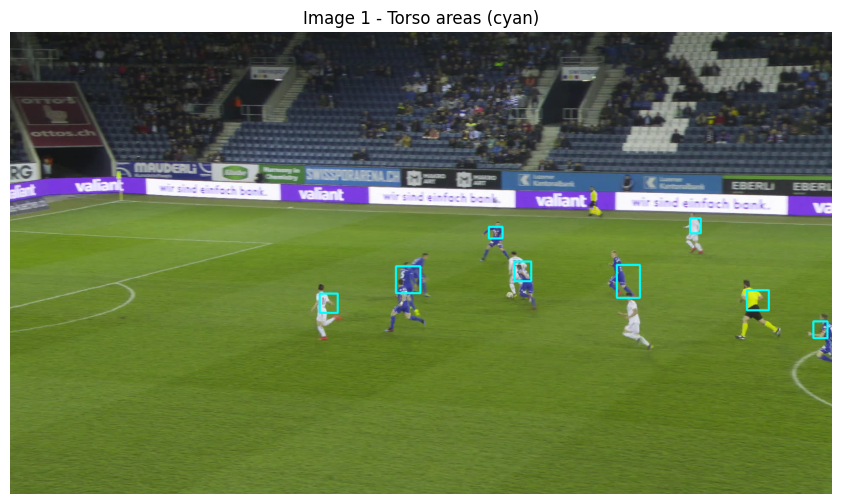

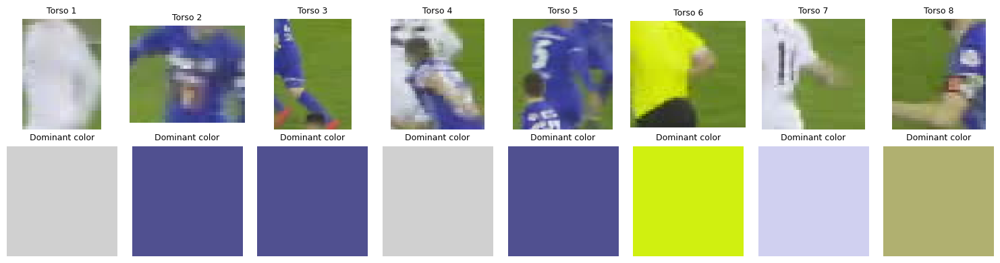

In [ ]:
#Shirt colors of the people found in image 1
shown = boxes1[:8]
drawn = image1_rgb.copy()
crops = []
swatches = []

for (x, y, w, h) in shown:
    #1. Torso crop: 15%-50% of the height and the middle 60% of the width
    tx1 = int(x + 0.2 * w)
    tx2 = int(x + 0.8 * w)
    ty1 = int(y + 0.15 * h)
    ty2 = int(y + 0.5 * h)
    cv2.rectangle(drawn, (tx1, ty1), (tx2, ty2), (0, 255, 255), 3)         #torso area in cyan

    crop = image1[ty1:ty2, tx1:tx2]
    crop_grass = grass_open1[ty1:ty2, tx1:tx2]
    crops.append(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))

    #2. Keeping only the pixels that are not grass (a list of pixels, each one with 3 values B, G, R)
    pixels = crop[crop_grass == 0]

    #3. Dominant color: each channel goes from 0-255 to 0-7 (levels of 32), and the three levels
    #are combined into one number from 0 to 511 (astype(int) is needed because the numbers get bigger than 255)
    q = pixels.astype(int) // 32
    ids = q[:, 0] * 64 + q[:, 1] * 8 + q[:, 2]

    #[NEW CODE] np.bincount counts how many pixels got each number. np.argmax gives the most common one
    counts = np.bincount(ids, minlength=512)
    best = int(np.argmax(counts))

    #Center of the winning color (back to a normal 0-255 color: B, G, R)
    b_val = (best // 64) * 32 + 16
    g_val = ((best // 8) % 8) * 32 + 16
    r_val = (best % 8) * 32 + 16

    #Small square of that color (as RGB) to display it
    swatch = np.zeros((20, 20, 3), dtype=np.uint8)
    swatch[:, :] = [r_val, g_val, b_val]
    swatches.append(swatch)

plt.figure(figsize=(15, 6))
plt.imshow(drawn)
plt.title("Image 1 - Torso areas (cyan)")
plt.axis("off")
plt.show()

plt.figure(figsize=(15, 4))
for k in range(len(shown)):
    plt.subplot(2, 8, k + 1)
    plt.imshow(crops[k])
    plt.title("Torso " + str(k + 1), fontsize=9)
    plt.axis("off")

    plt.subplot(2, 8, 8 + k + 1)
    plt.imshow(swatches[k])
    plt.title("Dominant color", fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

> **[ASSESSMENT] Shirt color.**
> *Why the torso?* The torso is where the shirt color is; the head is skin and hair, the legs are shorts and socks (a different color).
> *Why remove grass pixels?* Part of the crop can be the grass behind the player; if we kept it, every shirt would look a bit green.
> *Why dominant color and not the average?* Averaging a red shirt with white stripes gives pink, a color that is not on the shirt. The most common quantized color is a real color on the shirt.
> *What are the weak points?* Small players have a very small torso with few pixels, motion blur mixes colors, and two overlapping players share a blob.

# PART 4 - Running the Pipeline on All Frames and Measuring Detection

Steps 1-4 of Part 3 are now packaged into one **function**, `find_people`. It is **the same code** as in Part 3, just wrapped with a name so we can run it on every frame and test different settings without copy-pasting it dozens of times. Then we measure how good the detection is using the ground-truth boxes.

**How we measure (explained from zero).**

- **IoU (intersection over union)** compares two boxes: the area where they overlap divided by the area they cover together. 1 = identical, 0 = no overlap. We say our box *matches* a ground-truth person if IoU is at least 0.3 (a fairly generous value, because our blobs are tight around the body while labeled boxes can be looser).
- **Recall** = of all the people in the ground truth, what fraction did we find? (Misses lower it.)
- **Precision** = of all the boxes we drew, what fraction are really people? (False alarms lower it.)
- Both matter: drawing a box on everything gives high recall and bad precision; drawing very few boxes gives the opposite.

The ground truth is used **only to measure**. The pipeline itself never sees the labels.

In [ ]:
#Settings of the pipeline (the same values used in Part 3)
hue_low = 35
hue_high = 85
sat_min = 40
val_min = 40
open_grass = 5          #opening size for the grass mask
close_pitch = 25        #closing size to rejoin the grass pieces split by the pitch lines
open_people = 7         #opening size to remove the pitch lines from the people mask
close_people = 5        #closing size to join the pieces of a person
min_area = 300
min_height = 20
min_aspect = 0.8
max_aspect = 5.0
max_area_fraction = 0.05

#[NEW CODE] A function is a block of code with a name. The values in the parentheses (image_bgr, h_low, ...) are
#what we give to it, and "return" gives the results back. This one repeats Steps 1-4 of Part 3 and returns the grass mask,
#the field region, the cleaned non-grass mask and the list of boxes (x, y, w, h).
#The four values we will want to change in the tests (h_low, h_high, s_min, k_open) are inputs; the rest are the settings above.
def find_people(image_bgr, h_low, h_high, s_min, k_open):
    #Step 1: grass mask
    hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)
    grass = ((hsv[:, :, 0] >= h_low) & (hsv[:, :, 0] <= h_high) & (hsv[:, :, 1] >= s_min) & (hsv[:, :, 2] >= val_min)).astype(np.uint8) * 255

    #Step 2: opening, closing to rejoin the pieces, biggest grass piece, convex hull
    k_grass = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (open_grass, open_grass))
    grass = cv2.morphologyEx(grass, cv2.MORPH_OPEN, k_grass)

    k_pitch = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (close_pitch, close_pitch))
    joined = cv2.morphologyEx(grass, cv2.MORPH_CLOSE, k_pitch)

    num, labels, stats, centroids = cv2.connectedComponentsWithStats(joined, connectivity=8)
    if num <= 1:
        return grass, np.zeros_like(grass), np.zeros_like(grass), []
    biggest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    pitch = (labels == biggest).astype(np.uint8) * 255

    contours, _ = cv2.findContours(pitch, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    hull = cv2.convexHull(max(contours, key=cv2.contourArea))
    field = np.zeros_like(grass)
    cv2.fillConvexPoly(field, hull, 255)

    #Step 3: non-grass inside the field, then opening (lines) and closing (join pieces)
    non_grass = cv2.bitwise_and(field, cv2.bitwise_not(grass))
    k_open_people = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_open, k_open))
    k_close_people = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (close_people, close_people))
    non_grass = cv2.morphologyEx(non_grass, cv2.MORPH_OPEN, k_open_people)
    non_grass = cv2.morphologyEx(non_grass, cv2.MORPH_CLOSE, k_close_people)

    #Step 4: blobs -> boxes that look like a person
    num, labels, stats, centroids = cv2.connectedComponentsWithStats(non_grass, connectivity=8)
    img_h, img_w = non_grass.shape
    boxes = []
    for i in range(1, num):
        x = int(stats[i, cv2.CC_STAT_LEFT])
        y = int(stats[i, cv2.CC_STAT_TOP])
        w = int(stats[i, cv2.CC_STAT_WIDTH])
        h = int(stats[i, cv2.CC_STAT_HEIGHT])
        area = int(stats[i, cv2.CC_STAT_AREA])
        if area < min_area or h < min_height:
            continue
        if area > max_area_fraction * img_h * img_w:
            continue
        if h / w < min_aspect or h / w > max_aspect:
            continue
        boxes.append((x, y, w, h))
    return grass, field, non_grass, boxes

#IoU of two boxes (x, y, w, h): overlap area divided by the area they cover together
def iou(a, b):
    ax, ay, aw, ah = a
    bx, by, bw, bh = b
    x1 = max(ax, bx)
    y1 = max(ay, by)
    x2 = min(ax + aw, bx + bw)
    y2 = min(ay + ah, by + bh)
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    union = aw * ah + bw * bh - inter
    if union <= 0:
        return 0
    return inter / union

#For one frame: was each ground-truth person found (hits)? and how many of our boxes are real people (good_pred)?
def evaluate_frame(pred_boxes, gt_people):
    hits = []
    for g in gt_people:
        gbox = (g["x"], g["y"], g["w"], g["h"])
        best = 0
        for pbox in pred_boxes:
            best = max(best, iou(gbox, pbox))
        hits.append(best >= 0.3)

    good_pred = 0
    for pbox in pred_boxes:
        best = 0
        for g in gt_people:
            best = max(best, iou((g["x"], g["y"], g["w"], g["h"]), pbox))
        if best >= 0.3:
            good_pred += 1
    return hits, good_pred

In [ ]:
#Running the pipeline on every frame and measuring it
total_gt = 0
total_hit = 0
total_pred = 0
total_good = 0
gt_heights = []        #height of each ground-truth person
gt_hits = []           #was that person found?

for i, f in enumerate(frames):
    grass, field, non_grass, pred_boxes = find_people(f["image"], hue_low, hue_high, sat_min, open_people)
    hits, good_pred = evaluate_frame(pred_boxes, f["people"])

    #Saving what we need later inside the frame
    f["grass"] = grass
    f["pred"] = pred_boxes
    f["n_gt"] = len(f["people"])

    #Recall, precision and F1 (a single number that combines both) of this frame
    rec = 0
    if len(hits) > 0:
        rec = sum(hits) / len(hits)
    prec = 0
    if len(pred_boxes) > 0:
        prec = good_pred / len(pred_boxes)
    f["f1"] = 0
    if rec + prec > 0:
        f["f1"] = 2 * rec * prec / (rec + prec)

    total_gt += len(f["people"])
    total_hit += sum(hits)
    total_pred += len(pred_boxes)
    total_good += good_pred
    for g in f["people"]:
        gt_heights.append(g["h"])
    gt_hits += hits

    if (i + 1) % 10 == 0:
        print("Processed", i + 1, "of", len(frames), "frames")

print()
print("People in the ground truth:", total_gt, ", boxes we drew:", total_pred)
print("Recall (people found):", round(total_hit / total_gt, 3))
print("Precision (our boxes that are people):", round(total_good / total_pred, 3))

Processed 10 of 60 frames
Processed 20 of 60 frames
Processed 30 of 60 frames
Processed 40 of 60 frames
Processed 50 of 60 frames
Processed 60 of 60 frames

People in the ground truth: 916 , boxes we drew: 677
Recall (people found): 0.681
Precision (our boxes that are people): 0.832


## [PRESENTATION] Does the size of the player matter?

The proposal said we would look at how accuracy changes with small players. Here is the recall for small, medium and large people (box height in pixels).

Small (< 40 px): 6 people, recall 0.0
Medium (40-80 px): 57 people, recall 0.474
Large (> 80 px): 853 people, recall 0.7


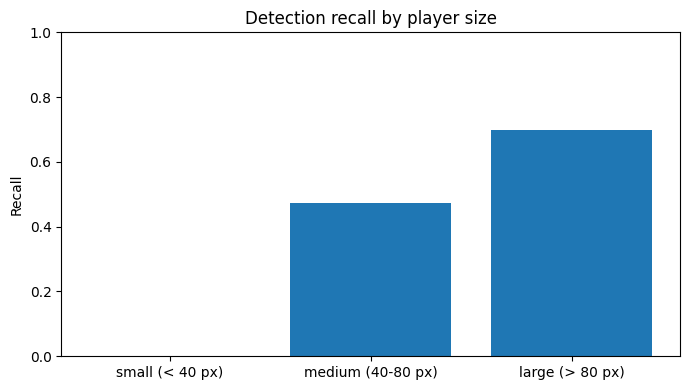

In [ ]:
gt_heights = np.array(gt_heights)
gt_hits = np.array(gt_hits)

#Height groups: smaller than 40 pixels, 40-80, bigger than 80
small = gt_heights < 40
medium = (gt_heights >= 40) & (gt_heights < 80)
large = gt_heights >= 80

recall_small = gt_hits[small].mean() if small.sum() > 0 else 0
recall_medium = gt_hits[medium].mean() if medium.sum() > 0 else 0
recall_large = gt_hits[large].mean() if large.sum() > 0 else 0

print("Small (< 40 px):", int(small.sum()), "people, recall", round(float(recall_small), 3))
print("Medium (40-80 px):", int(medium.sum()), "people, recall", round(float(recall_medium), 3))
print("Large (> 80 px):", int(large.sum()), "people, recall", round(float(recall_large), 3))

plt.figure(figsize=(7, 4))
plt.bar(["small (< 40 px)", "medium (40-80 px)", "large (> 80 px)"], [recall_small, recall_medium, recall_large])
plt.ylim(0, 1)
plt.title("Detection recall by player size")
plt.ylabel("Recall")
plt.tight_layout()
plt.show()

## [PRESENTATION] Hyperparameters of the detection

Which settings affect the result? We change **one setting at a time** (the first line is the default) and measure recall and precision. To save time, these tests use every second frame.

> **[ASSESSMENT] Hyperparameter effect (you should be able to say the *trends*, not the numbers).**
> - *Hue range:* too narrow loses grass in sun or shadow, which makes false "people" shapes; too wide includes other things (like green kits) in the grass.
> - *Minimum saturation:* a low value lets grey and white regions count as grass, so pitch lines can disappear into the grass; a high value drops pale grass.
> - *Opening size for the people:* too small leaves the pitch lines (many false boxes, lower precision); too big erases thin or small players (lower recall).

In [ ]:
#Frames used for the tests (every second frame, to save time)
exp_frames = frames[::2]

#Each test is: name, hue low, hue high, minimum saturation, opening size for the people
tests = [
    ("default", 35, 85, 40, 7),
    ("hue 30-90", 30, 90, 40, 7),
    ("hue 40-80", 40, 80, 40, 7),
    ("hue 45-75", 45, 75, 40, 7),
    ("min saturation 20", 35, 85, 20, 7),
    ("min saturation 60", 35, 85, 60, 7),
    ("min saturation 80", 35, 85, 80, 7),
    ("opening size 3", 35, 85, 40, 3),
    ("opening size 5", 35, 85, 40, 5),
    ("opening size 9", 35, 85, 40, 9),
    ("opening size 11", 35, 85, 40, 11),
]

for name, h_low, h_high, s_min, k_open in tests:
    gt_total = 0
    hit_total = 0
    pred_total = 0
    good_total = 0

    for f in exp_frames:
        grass, field, non_grass, pred_boxes = find_people(f["image"], h_low, h_high, s_min, k_open)
        hits, good_pred = evaluate_frame(pred_boxes, f["people"])
        gt_total += len(hits)
        hit_total += sum(hits)
        pred_total += len(pred_boxes)
        good_total += good_pred

    recall = hit_total / gt_total
    precision = good_total / pred_total if pred_total > 0 else 0
    print(name, ": recall", round(recall, 3), ", precision", round(precision, 3))

default : recall 0.671 , precision 0.841
hue 30-90 : recall 0.645 , precision 0.735
hue 40-80 : recall 0.084 , precision 0.193
hue 45-75 : recall 0.002 , precision 0.043
min saturation 20 : recall 0.637 , precision 0.71
min saturation 60 : recall 0.675 , precision 0.794
min saturation 80 : recall 0.641 , precision 0.854
opening size 3 : recall 0.619 , precision 0.909
opening size 5 : recall 0.66 , precision 0.888
opening size 9 : recall 0.699 , precision 0.759
opening size 11 : recall 0.697 , precision 0.703


# PART 5 - Grouping People into Teams, Referees and Goalkeepers

Each person is now described by one color (the dominant torso color, three numbers B, G, R). We group those colors with **K-means**.

**K-means in plain words.**
1. Choose K and put K "centers" (starting colors) somewhere in color space.
2. Give every person to the nearest center.
3. Move each center to the average color of the people it received.
4. Repeat 2 and 3 until nothing changes.

It is *unsupervised*: it never sees the labels, it only sees colors. Two teams in different colors, a referee in a third color and goalkeepers in yet another color should appear as separate groups. A good choice is **K = 5**: team A, team B, referees, goalkeeper A, goalkeeper B (the same five groups used in the paper of my literature review).

**Two ways to cluster.** Our frames are meant to be independent stills, but a match has fixed kits, so we compare:
- **per image:** cluster the people of one frame only (truly independent stills, but few people per frame),
- **per clip:** cluster all the frames of the same clip together (more data, as if the kits of the match were learned from several photos of it).

**How we measure.**
- **Team accuracy** (players only, K = 2): the clusters are anonymous (cluster 0 is not "left"), so we try both ways of naming the two clusters and keep the better one.
- **Purity** (everyone, K = 5): in each cluster, take the most common true group (left player, right player, goalkeeper, referee...). Purity is the fraction of people who belong to the majority group of their cluster. 1.0 = every cluster contains only one kind of person.

**Two experiments.** First with the **ground-truth boxes** (this shows how good the color grouping is on its own, an upper bound), then with **our detected boxes** (the real, complete pipeline).

## Step 5 again as a function
`shirt_colours` repeats Step 5 of Part 3 (torso crop, remove grass, dominant color) and also computes the plain average color, so we can compare both.

In [ ]:
#Shirt color of one person: returns (dominant color, average color), both in B, G, R. Returns (None, None) if there are too few pixels
def shirt_colours(image_bgr, grass, box):
    img_h, img_w = grass.shape
    x, y, w, h = box

    #Torso crop (15%-50% of the height, middle 60% of the width), kept inside the image
    tx1 = max(0, min(int(x + 0.2 * w), img_w))
    tx2 = max(0, min(int(x + 0.8 * w), img_w))
    ty1 = max(0, min(int(y + 0.15 * h), img_h))
    ty2 = max(0, min(int(y + 0.5 * h), img_h))
    if tx2 - tx1 < 2 or ty2 - ty1 < 2:
        return None, None

    crop = image_bgr[ty1:ty2, tx1:tx2]
    crop_grass = grass[ty1:ty2, tx1:tx2]

    #Only the pixels that are not grass
    pixels = crop[crop_grass == 0]
    if len(pixels) < 10:
        return None, None

    #Average color
    mean_colour = pixels.mean(axis=0)

    #Dominant color (most common quantized color)
    q = pixels.astype(int) // 32
    ids = q[:, 0] * 64 + q[:, 1] * 8 + q[:, 2]
    best = int(np.argmax(np.bincount(ids, minlength=512)))
    mode_colour = np.array([(best // 64) * 32 + 16, ((best // 8) % 8) * 32 + 16, (best % 8) * 32 + 16], dtype=float)

    return mode_colour, mean_colour

#K-means on the colors, separately for each group (a group is a clip, or a single image).
#colours = one color per person (a table with 3 columns), group_ids = the group number of each person.
#Returns the cluster number of each person (-1 if its group has fewer than K people) and the center color of its cluster
def cluster_groups(colours, group_ids, K):
    clusters = np.full(len(colours), -1)
    centres = np.zeros((len(colours), 3))

    #Stop after 50 rounds or when the centers move less than 0.5
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 50, 0.5)

    for g in np.unique(group_ids):
        idx = np.where(group_ids == g)[0]          #positions of the people of this group
        if len(idx) < K:
            continue

        data = np.float32(colours[idx])
        cv2.setRNGSeed(481)                        #fixed seed, so the results are the same every run
        #cv2.kmeans(data, K, no initial labels, stop rule, 10 attempts (keeps the best), smart starting centers)
        compactness, labels, centers = cv2.kmeans(data, K, None, criteria, 10, cv2.KMEANS_PP_CENTERS)
        labels = labels.flatten()
        clusters[idx] = labels
        centres[idx] = centers[labels]
    return clusters, centres

#Team accuracy for players clustered with K = 2. Only groups where both teams are present are counted
def team_accuracy(clusters, labels, group_ids):
    correct = 0
    total = 0
    groups_used = 0
    for g in np.unique(group_ids):
        sel = (group_ids == g) & (clusters >= 0)
        lab = labels[sel]
        cl = clusters[sel]
        if np.sum(lab == "player_left") == 0 or np.sum(lab == "player_right") == 0:
            continue
        #People for whom "cluster 0 = left team" is right. The other naming gives the opposite count
        same = int(np.sum((cl == 0) == (lab == "player_left")))
        correct += max(same, len(lab) - same)
        total += len(lab)
        groups_used += 1
    if total == 0:
        return 0, 0
    return correct / total, groups_used

#Purity of the clusters: fraction of people who have the most common true group of their cluster ("none" boxes are ignored)
def purity(clusters, labels, group_ids):
    good = 0
    total = 0
    for g in np.unique(group_ids):
        for c in np.unique(clusters[group_ids == g]):
            if c < 0:
                continue
            sel = (group_ids == g) & (clusters == c) & (labels != "none")
            if sel.sum() == 0:
                continue
            values, counts = np.unique(labels[sel], return_counts=True)
            good += counts.max()
            total += sel.sum()
    if total == 0:
        return 0
    return good / total

## Building the table of people

One row per person: its shirt colors (dominant and average), its clip number, its frame number and its true group. Two tables: one for the **ground-truth boxes** and one for **our detected boxes**. For a detected box, the true group is the group of the ground-truth person it matches (IoU of at least 0.3), or `"none"` if it matches nobody (a false alarm).

In [ ]:
#Table 1: people from the ground-truth boxes
gt_mode = []          #dominant shirt color
gt_mean = []          #average shirt color
gt_clip = []          #clip number
gt_frame = []         #frame number
gt_label = []         #true group
gt_is_player = []     #is it a player? (True / False)

for i, f in enumerate(frames):
    for g in f["people"]:
        box = (int(g["x"]), int(g["y"]), int(g["w"]), int(g["h"]))
        mode_c, mean_c = shirt_colours(f["image"], f["grass"], box)
        if mode_c is None:
            continue
        gt_mode.append(mode_c)
        gt_mean.append(mean_c)
        gt_clip.append(f["clip_id"])
        gt_frame.append(i)
        gt_label.append(g["label"])
        gt_is_player.append(g["role"] == "player")

#Lists to arrays, so we can select people with True / False masks
gt_mode = np.array(gt_mode)
gt_mean = np.array(gt_mean)
gt_clip = np.array(gt_clip)
gt_frame = np.array(gt_frame)
gt_label = np.array(gt_label)
gt_is_player = np.array(gt_is_player)
print("People in the ground-truth table:", len(gt_label))

#Table 2: people from OUR detected boxes
det_mode = []
det_clip = []
det_frame = []
det_label = []
det_box = []
det_is_player = []

for i, f in enumerate(frames):
    for pbox in f["pred"]:
        #Which ground-truth person does this box match best?
        best = 0
        best_label = "none"
        for g in f["people"]:
            v = iou((g["x"], g["y"], g["w"], g["h"]), pbox)
            if v > best:
                best = v
                best_label = g["label"]
        if best < 0.3:
            best_label = "none"

        mode_c, mean_c = shirt_colours(f["image"], f["grass"], pbox)
        if mode_c is None:
            continue
        det_mode.append(mode_c)
        det_clip.append(f["clip_id"])
        det_frame.append(i)
        det_label.append(best_label)
        det_box.append(pbox)
        det_is_player.append(best_label.startswith("player_"))

det_mode = np.array(det_mode)
det_clip = np.array(det_clip)
det_frame = np.array(det_frame)
det_label = np.array(det_label)
det_is_player = np.array(det_is_player)

print("Detected boxes with a color:", len(det_label), ", matched to a real person:", int(np.sum(det_label != "none")))

People in the ground-truth table: 911
Detected boxes with a color: 676 , matched to a real person: 563


## Experiment 5A - Team accuracy with ground-truth boxes (color grouping on its own)

Players only, K = 2. We compare the two shirt-color descriptors (dominant color vs average color) and the two clustering scopes (per clip vs per image).

In [ ]:
print("TEAM ACCURACY (ground-truth boxes, players only, K = 2)")

#Players only: gt_is_player is a True / False mask
labels_p = gt_label[gt_is_player]

for color_name, colours in [("dominant color", gt_mode), ("average color", gt_mean)]:
    colours_p = colours[gt_is_player]

    #Clustering each clip separately
    clusters, centres = cluster_groups(colours_p, gt_clip[gt_is_player], 2)
    acc, used = team_accuracy(clusters, labels_p, gt_clip[gt_is_player])
    print("  ", color_name, ", cluster per clip: accuracy", round(acc, 3), "(groups evaluated:", used, ")")

    #Clustering each image separately
    clusters, centres = cluster_groups(colours_p, gt_frame[gt_is_player], 2)
    acc, used = team_accuracy(clusters, labels_p, gt_frame[gt_is_player])
    print("  ", color_name, ", cluster per image: accuracy", round(acc, 3), "(groups evaluated:", used, ")")

TEAM ACCURACY (ground-truth boxes, players only, K = 2)
   dominant color , cluster per clip: accuracy 0.897 (groups evaluated: 6 )
   dominant color , cluster per image: accuracy 0.9 (groups evaluated: 60 )
   average color , cluster per clip: accuracy 0.922 (groups evaluated: 6 )
   average color , cluster per image: accuracy 0.926 (groups evaluated: 60 )


## Experiment 5B - How many groups? Purity for different K (ground-truth boxes)

All people (players, goalkeepers, referees), clustered per clip. If K = 5 is the right choice, purity should be high at K = 5 and should not improve much when K grows.

In [ ]:
print("PURITY (ground-truth boxes, everyone, dominant color, cluster per clip)")
for K in [2, 3, 4, 5, 6]:
    clusters, centres = cluster_groups(gt_mode, gt_clip, K)
    print("  K =", K, ": purity", round(purity(clusters, gt_label, gt_clip), 3))

PURITY (ground-truth boxes, everyone, dominant color, cluster per clip)
  K = 2 : purity 0.797
  K = 3 : purity 0.869
  K = 4 : purity 0.883
  K = 5 : purity 0.902
  K = 6 : purity 0.905


## Experiment 5C - The real pipeline: our detected boxes

Now the boxes come from our own detection (Part 4). Boxes that do not match any ground-truth person have the group `"none"` and are ignored when measuring, but they are still clustered (the pipeline does not know which boxes are wrong).

In [ ]:
#Team accuracy: cluster only the detected boxes that match a player, K = 2
labels_p = det_label[det_is_player]

clusters, centres = cluster_groups(det_mode[det_is_player], det_clip[det_is_player], 2)
acc, used = team_accuracy(clusters, labels_p, det_clip[det_is_player])
print("TEAM ACCURACY, detected boxes, cluster per clip :", round(acc, 3), "(groups evaluated:", used, ")")

clusters, centres = cluster_groups(det_mode[det_is_player], det_frame[det_is_player], 2)
acc, used = team_accuracy(clusters, labels_p, det_frame[det_is_player])
print("TEAM ACCURACY, detected boxes, cluster per image:", round(acc, 3), "(groups evaluated:", used, ")")

#Purity with K = 5 on all the detected boxes (these K = 5 clusters are also used for the figures of Part 6)
det_clusters, det_centres = cluster_groups(det_mode, det_clip, 5)
print("PURITY, detected boxes, K = 5, cluster per clip:", round(purity(det_clusters, det_label, det_clip), 3))

TEAM ACCURACY, detected boxes, cluster per clip : 0.915 (groups evaluated: 6 )
TEAM ACCURACY, detected boxes, cluster per image: 0.917 (groups evaluated: 56 )
PURITY, detected boxes, K = 5, cluster per clip: 0.899


> **[ASSESSMENT] Evaluation questions.**
> *How do you evaluate?* Detection: recall and precision with IoU >= 0.3 against the dataset boxes. Teams: accuracy with K = 2 on players (trying both cluster namings) and purity with K = 5 on everyone. Qualitative: example frames with successes and failures.
> *Why two kinds of experiments?* The ground-truth boxes show how good the color grouping is when detection is perfect; the detected boxes show the full pipeline. The gap between them is the cost of detection errors.
> *What did you compare?* Dominant color vs average color; clustering per clip vs per image; different K; different grass and morphology settings.
> *Ballpark numbers?* Say them like this: "with method A the accuracy was around X%, with method B around Y%." Copy X and Y from the tables above.
> *Why K-means and not something else?* It is simple, covered in the course, needs no labels, and the benchmark paper's own baseline also uses it for teams.

# PART 6 - Success and Failure Examples

## [PRESENTATION] Best and worst frames

Frames are ranked by their detection F1 score. The first two below are the best frames and the last two are the worst. Our boxes are drawn in the **color of their K-means group center** (so a box is drawn in the color of the shirt group the pipeline assigned it to), and the ground truth is in thin white.

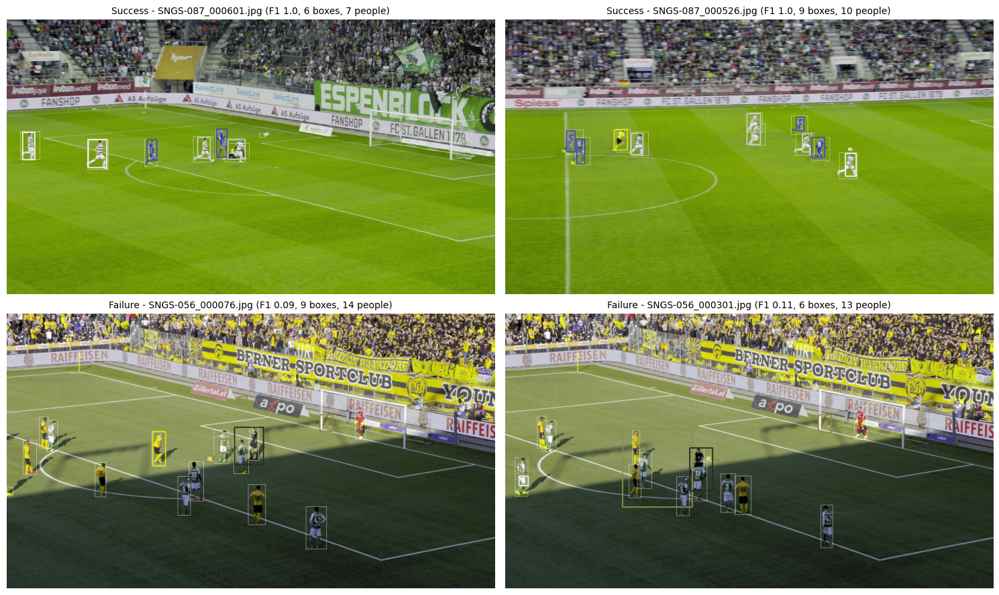

In [ ]:
#Frames with at least 5 labeled people, sorted by F1 (lowest first)
ranked = []
for i, f in enumerate(frames):
    if f["n_gt"] >= 5:
        ranked.append((f["f1"], i))
ranked.sort()

#Two best frames, then the two worst
gallery_ids = [ranked[-1][1], ranked[-2][1], ranked[0][1], ranked[1][1]]
gallery_titles = ["Success", "Success", "Failure", "Failure"]

plt.figure(figsize=(15, 9))

for k in range(4):
    i = gallery_ids[k]
    drawn = cv2.cvtColor(frames[i]["image"], cv2.COLOR_BGR2RGB)

    #Ground truth (thin white)
    for g in frames[i]["boxes"]:
        cv2.rectangle(drawn, (int(g["x"]), int(g["y"])), (int(g["x"] + g["w"]), int(g["y"] + g["h"])), (255, 255, 255), 1)

    #Our boxes, in the color of their cluster center (grey if the person was not clustered)
    for j in range(len(det_frame)):
        if det_frame[j] != i:
            continue
        x, y, w, h = det_box[j]
        if det_clusters[j] < 0:
            colour = (128, 128, 128)
        else:
            colour = (int(det_centres[j][2]), int(det_centres[j][1]), int(det_centres[j][0]))      #BGR -> RGB
        cv2.rectangle(drawn, (x, y), (x + w, y + h), colour, 3)

    plt.subplot(2, 2, k + 1)
    plt.imshow(drawn)
    plt.title(gallery_titles[k] + " - " + frames[i]["name"] + " (F1 " + str(round(frames[i]["f1"], 2)) + ", " + str(len(frames[i]["pred"])) + " boxes, " + str(frames[i]["n_gt"]) + " people)", fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()

## Look at the Pipeline Stages of a Failure Frame

To understand *why* a frame failed, look at its intermediate masks. This is exactly the habit the assessment asks about ("what worked, what did not, and what you changed").

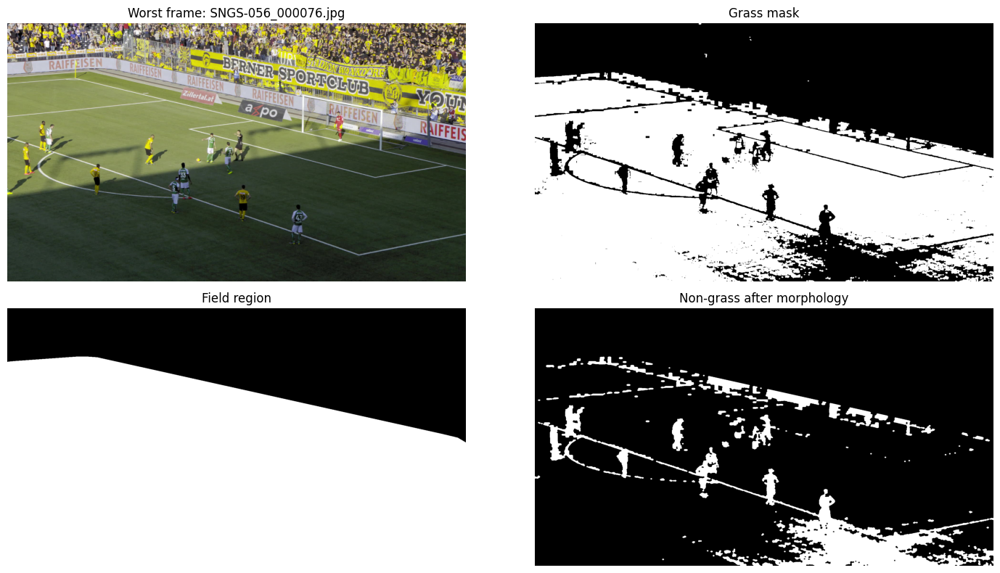

In [ ]:
#Intermediate masks of the worst frame
worst = gallery_ids[2]
grass_w, field_w, non_grass_w, boxes_w = find_people(frames[worst]["image"], hue_low, hue_high, sat_min, open_people)

plt.figure(figsize=(15, 8))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(frames[worst]["image"], cv2.COLOR_BGR2RGB))
plt.title("Worst frame: " + frames[worst]["name"])
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(grass_w, cmap="gray")
plt.title("Grass mask")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(field_w, cmap="gray")
plt.title("Field region")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(non_grass_w, cmap="gray")
plt.title("Non-grass after morphology")
plt.axis("off")

plt.tight_layout()
plt.show()

# PART 7 - Sources of Error, Conclusion and Study Guide

## [PRESENTATION] Main sources of error (write YOUR observations here)

The course asks for **your own** analysis, so after looking at your figures, fill this in with what you actually saw. These are the usual suspects to check for; keep the ones that appear in your failure frames and delete the others:

- **Small, far-away players:** removed by the size filter or too few pixels in the torso for a reliable color (see the recall by size in Part 4).
- **Overlapping players:** touching players form one blob, so one box covers two people and one color is shared.
- **Kits similar to the grass:** a green goalkeeper or referee shirt is classified as grass and disappears.
- **Shadows and lighting:** shadowed grass can fall outside the hue/value range and become a false "person".
- **Things inside the field that are not people:** the ball, advertising boards on the sideline, pitch markings.
- **Teams with similar kit colors**, or goalkeepers and referees in colors close to a team: K-means cannot separate them (see purity).
- **Wrong field region:** the convex hull is wrong if the visible pitch is not convex or green objects appear elsewhere.

**My observations (fill in):**
- The pipeline works well when ...
- It fails when ...
- The setting that mattered the most was ...

## [PRESENTATION] Preliminary conclusion

- *Main findings:* (summarize your detection recall and precision, team accuracy and purity numbers in one or two sentences)
- *What I learned:* (for example, how much of the work is choosing good color spaces and cleaning masks with morphology)
- *Ideas to improve:* adapt the grass thresholds per image (for example, from the most common hue in the image), split touching players (for example, with distance-transform based methods), use color distance in a perceptual color space (Lab) for K-means, and separate goalkeepers and referees with extra cues.

## Video checklist (4-5 minutes, your own voice)

1. Say your name and the project title (Part 0).
2. Problem and why it matters; show the input and desired output figure (Part 2).
3. Pipeline diagram and one example for each step (Part 0 and Part 3).
4. Say which libraries you used (the table at the top).
5. Dataset: clips, frames, people per frame, small players (Part 2).
6. Preliminary results: detection recall and precision, team accuracy and purity (Parts 4 and 5), how you will finish the evaluation and which settings you studied.
7. Show a success and a failure example and the main sources of error (Part 6).
8. Conclusion: findings, what you learned, ideas to improve (above).

## Study guide for the assessment (the things this notebook lets you say)

- **Pipeline from memory:** HSV grass mask, opening, closing to rejoin the pitch, biggest piece, convex hull, non-grass inside the field, opening and closing, connected components, size and shape filter, torso crop, dominant color, K-means.
- **Course concepts used:** color spaces (HSV), thresholding, morphology (opening, closing, structuring element, convex hull), connected components, color descriptors (dominant color), K-means clustering.
- **Which parts are library and which are ours:** the algorithms (HSV conversion, morphology, components, K-means) come from OpenCV; the design of the pipeline, the settings, the torso rule, the evaluation and the experiments are ours.
- **Dataset:** SoccerNet-GSR, a few clips with evenly spaced frames, ballpark sizes, the noise in the images.
- **Evaluation:** IoU, recall, precision, team accuracy, purity, and why we need both ground-truth boxes and detected boxes.
- **Hyperparameters:** the trends of the hue range, minimum saturation, opening size, K, color descriptor and clustering scope.
- **Timeline story:** first look at the data and the labels, then the grass mask, then morphology to clean it, then the people blobs, then colors and K-means, then evaluation and tuning.
- **No pretrained models anywhere.**